# Response quality evaluation

Paste the JSON returned by `POST /chat/query` into the cell below and run all cells. Nothing is recomputed here: the notebook only reads the `evaluation` field, which the backend adds when `INCLUDE_EVAL_DATA=true`.

- **Graph 1**: cosine similarity between the query and each retrieved chunk, per query type (cited vs not cited).
- **Graph 2**: cosine similarity between the LLM answer and the chunks it cited (bars per citation, plus a response x citation heatmap).

The sample data is synthetic. Responses without `evaluation` (older backend) are skipped with a message.

## 1. Paste responses

In [1]:
# --- PASTE CELL -------------------------------------------------------------
# Optional: force a query type. Keys: 0-based response index OR a lowercase
# substring of the question. Anything not listed uses the keyword classifier.
QUERY_TYPES = {
    # 0: "factual",
    # "working capital": "factual",
}

# Paste one ChatResponse JSON (from POST /chat/query) per triple-quoted string.
# A single string containing several JSON objects back to back also works.
# The sample below is synthetic; replace it with your own responses.
RAW = [
r"""
{
  "response": "The single discretionary allowance is R1 million per calendar year per adult [1][3].\n\nSources: [1], [3]",
  "history": [
    {
      "additionalProp1": {}
    },
    {
      "role": "user",
      "content": "What is the limit for a single discretionary allowance per calendar year?"
    },
    {
      "role": "assistant",
      "content": "The single discretionary allowance is R1 million per calendar year per adult [1][3].\n\nSources: [1], [3]"
    }
  ],
  "retrieved_chunks": 7,
  "citations": [
    {
      "document_id": "51db0cb8-1099-4b9f-949c-0e4de4afcfe0",
      "child_id": "c_f2a752e6b438",
      "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
      "section_id": "I.3",
      "clause_path": "I.3(C)(i)",
      "heading": "Short-term trade finance",
      "printed_page_start": "252",
      "printed_page_end": "252",
      "pdf_page_start": 252,
      "pdf_page_end": 252,
      "page_revisions": [
        "6/2021"
      ],
      "label": "I.3(C)(i), p. 252 · rev. 6/2021",
      "markers": [
        1
      ]
    },
    {
      "document_id": "51db0cb8-1099-4b9f-949c-0e4de4afcfe0",
      "child_id": "c_d23f128b2f33",
      "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
      "section_id": "B.2",
      "clause_path": "B.2(A)(ii)",
      "heading": "Authorised Dealers in foreign exchange",
      "printed_page_start": "40",
      "printed_page_end": "40",
      "pdf_page_start": 40,
      "pdf_page_end": 40,
      "page_revisions": [
        "6/2021"
      ],
      "label": "B.2(A)(ii), p. 40 · rev. 6/2021",
      "markers": [
        3
      ]
    }
  ],
  "evaluation": {
    "query_embedding_model": "huggingface/BAAI/bge-small-en-v1.5",
    "retrieved": [
      {
        "marker": 1,
        "rank": 1,
        "child_id": "c_f2a752e6b438",
        "parent_id": "p_269e0d37",
        "relation": "primary",
        "similarity": 0.82,
        "cited": true,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "I.3",
        "clause_path": "I.3(C)(i)",
        "heading": "Short-term trade finance",
        "label": "I.3(C)(i), p. 252 · rev. 6/2021",
        "chunk_text": "I.3(C)(i) Short-term trade finance. (Synthetic sample text for chunk 1: Authorised Dealers may ...)",
        "answer_similarity": 0.74
      },
      {
        "marker": 2,
        "rank": 2,
        "child_id": "c_a6a36513270e",
        "parent_id": "p_0c5c7fd0",
        "relation": "primary",
        "similarity": 0.61,
        "cited": false,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "B.4",
        "clause_path": "B.4(B)(i)",
        "heading": "Foreign currency accounts",
        "label": "B.4(B)(i), p. 98 · rev. 6/2021",
        "chunk_text": "B.4(B)(i) Foreign currency accounts. (Synthetic sample text for chunk 2: Authorised Dealers may ...)",
        "answer_similarity": 0.35
      },
      {
        "marker": 3,
        "rank": 3,
        "child_id": "c_d23f128b2f33",
        "parent_id": "p_892f902b",
        "relation": "primary",
        "similarity": 0.77,
        "cited": true,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "B.2",
        "clause_path": "B.2(A)(ii)",
        "heading": "Authorised Dealers in foreign exchange",
        "label": "B.2(A)(ii), p. 40 · rev. 6/2021",
        "chunk_text": "B.2(A)(ii) Authorised Dealers in foreign exchange. (Synthetic sample text for chunk 3: Authorised Dealers may ...)",
        "answer_similarity": 0.69
      },
      {
        "marker": 4,
        "rank": 4,
        "child_id": "c_5d9d1818e811",
        "parent_id": "p_9531985d",
        "relation": "primary",
        "similarity": 0.48,
        "cited": false,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "B.10",
        "clause_path": "B.10(B)(xvi)",
        "heading": "Short-term Insurance Act",
        "label": "B.10(B)(xvi), p. 128 · rev. 6/2021",
        "chunk_text": "B.10(B)(xvi) Short-term Insurance Act. (Synthetic sample text for chunk 4: Authorised Dealers may ...)",
        "answer_similarity": 0.4
      },
      {
        "marker": 5,
        "rank": 5,
        "child_id": "c_e8e20ed90475",
        "parent_id": "p_81e74ef5",
        "relation": "primary",
        "similarity": 0.41,
        "cited": false,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "I.4",
        "clause_path": "I.4(B)(iii)",
        "heading": "Loop structures",
        "label": "I.4(B)(iii), p. 262 · rev. 6/2021",
        "chunk_text": "I.4(B)(iii) Loop structures. (Synthetic sample text for chunk 5: Authorised Dealers may ...)",
        "answer_similarity": 0.33
      },
      {
        "marker": 6,
        "rank": 6,
        "child_id": "c_099936f675cc",
        "parent_id": "p_1600a35a",
        "relation": "primary",
        "similarity": 0.52,
        "cited": false,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "C.1",
        "clause_path": "C.1(A)(i)",
        "heading": "Import payments",
        "label": "C.1(A)(i), p. 140 · rev. 6/2021",
        "chunk_text": "C.1(A)(i) Import payments. (Synthetic sample text for chunk 6: Authorised Dealers may ...)",
        "answer_similarity": 0.45
      },
      {
        "marker": 7,
        "rank": 7,
        "child_id": "c_6b0d6f03675a",
        "parent_id": "p_11e20b8f",
        "relation": "primary",
        "similarity": 0.38,
        "cited": false,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "B.4",
        "clause_path": "B.4(B)(iii)",
        "heading": "Travel allowance",
        "label": "B.4(B)(iii), p. 101 · rev. 6/2021",
        "chunk_text": "B.4(B)(iii) Travel allowance. (Synthetic sample text for chunk 7: Authorised Dealers may ...)",
        "answer_similarity": 0.31
      }
    ]
  }
}
""",
r"""
What Are Graphs?

{
  "response": "Residents may hold foreign currency accounts subject to the conditions of B.4 [2][4][5].\n\nSources: [2], [4], [5]",
  "history": [
    {
      "role": "user",
      "content": "Summarise the rules for foreign currency accounts held by residents"
    },
    {
      "role": "assistant",
      "content": "Residents may hold foreign currency accounts subject to the conditions of B.4 [2][4][5].\n\nSources: [2], [4], [5]"
    }
  ],
  "retrieved_chunks": 7,
  "citations": [
    {
      "document_id": "51db0cb8-1099-4b9f-949c-0e4de4afcfe0",
      "child_id": "c_0f216cad4a26",
      "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
      "section_id": "I.4",
      "clause_path": "I.4(B)(iii)",
      "heading": "Loop structures",
      "printed_page_start": "262",
      "printed_page_end": "262",
      "pdf_page_start": 262,
      "pdf_page_end": 262,
      "page_revisions": [
        "6/2021"
      ],
      "label": "I.4(B)(iii), p. 262 · rev. 6/2021",
      "markers": [
        2
      ]
    },
    {
      "document_id": "51db0cb8-1099-4b9f-949c-0e4de4afcfe0",
      "child_id": "c_a17039263059",
      "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
      "section_id": "B.4",
      "clause_path": "B.4(B)(iii)",
      "heading": "Travel allowance",
      "printed_page_start": "101",
      "printed_page_end": "101",
      "pdf_page_start": 101,
      "pdf_page_end": 101,
      "page_revisions": [
        "6/2021"
      ],
      "label": "B.4(B)(iii), p. 101 · rev. 6/2021",
      "markers": [
        4
      ]
    },
    {
      "document_id": "51db0cb8-1099-4b9f-949c-0e4de4afcfe0",
      "child_id": "c_f29d953f48f1",
      "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
      "section_id": "D.1",
      "clause_path": "D.1(B)(ii)",
      "heading": "Export proceeds",
      "printed_page_start": "170",
      "printed_page_end": "170",
      "pdf_page_start": 170,
      "pdf_page_end": 170,
      "page_revisions": [
        "6/2021"
      ],
      "label": "D.1(B)(ii), p. 170 · rev. 6/2021",
      "markers": [
        5
      ]
    }
  ],
  "evaluation": {
    "query_embedding_model": "huggingface/BAAI/bge-small-en-v1.5",
    "retrieved": [
      {
        "marker": 1,
        "rank": 1,
        "child_id": "c_17383d9c1724",
        "parent_id": "p_8d116ece",
        "relation": "primary",
        "similarity": 0.66,
        "cited": false,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "B.10",
        "clause_path": "B.10(B)(xvi)",
        "heading": "Short-term Insurance Act",
        "label": "B.10(B)(xvi), p. 128 · rev. 6/2021",
        "chunk_text": "B.10(B)(xvi) Short-term Insurance Act. (Synthetic sample text for chunk 1: Authorised Dealers may ...)",
        "answer_similarity": 0.62
      },
      {
        "marker": 2,
        "rank": 2,
        "child_id": "c_0f216cad4a26",
        "parent_id": "p_d3ac94af",
        "relation": "primary",
        "similarity": 0.79,
        "cited": true,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "I.4",
        "clause_path": "I.4(B)(iii)",
        "heading": "Loop structures",
        "label": "I.4(B)(iii), p. 262 · rev. 6/2021",
        "chunk_text": "I.4(B)(iii) Loop structures. (Synthetic sample text for chunk 2: Authorised Dealers may ...)",
        "answer_similarity": 0.7
      },
      {
        "marker": 3,
        "rank": 3,
        "child_id": "c_1fb190c192cf",
        "parent_id": "p_f28c105d",
        "relation": "primary",
        "similarity": 0.58,
        "cited": false,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "C.1",
        "clause_path": "C.1(A)(i)",
        "heading": "Import payments",
        "label": "C.1(A)(i), p. 140 · rev. 6/2021",
        "chunk_text": "C.1(A)(i) Import payments. (Synthetic sample text for chunk 3: Authorised Dealers may ...)",
        "answer_similarity": 0.36
      },
      {
        "marker": 4,
        "rank": 4,
        "child_id": "c_a17039263059",
        "parent_id": "p_a09f76b5",
        "relation": "primary",
        "similarity": 0.71,
        "cited": true,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "B.4",
        "clause_path": "B.4(B)(iii)",
        "heading": "Travel allowance",
        "label": "B.4(B)(iii), p. 101 · rev. 6/2021",
        "chunk_text": "B.4(B)(iii) Travel allowance. (Synthetic sample text for chunk 4: Authorised Dealers may ...)",
        "answer_similarity": 0.66
      },
      {
        "marker": 5,
        "rank": 5,
        "child_id": "c_f29d953f48f1",
        "parent_id": "p_0fd630f1",
        "relation": "primary",
        "similarity": 0.64,
        "cited": true,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "D.1",
        "clause_path": "D.1(B)(ii)",
        "heading": "Export proceeds",
        "label": "D.1(B)(ii), p. 170 · rev. 6/2021",
        "chunk_text": "D.1(B)(ii) Export proceeds. (Synthetic sample text for chunk 5: Authorised Dealers may ...)",
        "answer_similarity": 0.58
      },
      {
        "marker": 6,
        "rank": 6,
        "child_id": "c_95e693bd04cf",
        "parent_id": "p_658cda14",
        "relation": "continuation",
        "similarity": 0.0,
        "cited": false,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "I.3",
        "clause_path": "I.3(C)(ii)",
        "heading": "Short-term working capital loans",
        "label": "I.3(C)(ii), p. 255 · rev. 6/2021",
        "chunk_text": "I.3(C)(ii) Short-term working capital loans. (Synthetic sample text for chunk 6: Authorised Dealers may ...)",
        "answer_similarity": 0.3
      },
      {
        "marker": 7,
        "rank": 7,
        "child_id": "c_f9eb0cb1e29c",
        "parent_id": "p_3898d190",
        "relation": "adjacent",
        "similarity": 0.0,
        "cited": false,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "I.3",
        "clause_path": "I.3(C)(i)",
        "heading": "Short-term trade finance",
        "label": "I.3(C)(i), p. 252 · rev. 6/2021",
        "chunk_text": "I.3(C)(i) Short-term trade finance. (Synthetic sample text for chunk 7: Authorised Dealers may ...)",
        "answer_similarity": 0.34
      }
    ]
  }
}
""",
r"""
{
  "response": "Trade finance relates to imports and exports [1], whereas working capital loans finance other current assets [2][6].\n\nSources: [1], [2], [6]",
  "history": [
    {
      "role": "user",
      "content": "Compare short-term trade finance and short-term working capital loans"
    },
    {
      "role": "assistant",
      "content": "Trade finance relates to imports and exports [1], whereas working capital loans finance other current assets [2][6].\n\nSources: [1], [2], [6]"
    }
  ],
  "retrieved_chunks": 7,
  "citations": [
    {
      "document_id": "51db0cb8-1099-4b9f-949c-0e4de4afcfe0",
      "child_id": "c_8e810becd7b0",
      "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
      "section_id": "C.1",
      "clause_path": "C.1(A)(i)",
      "heading": "Import payments",
      "printed_page_start": "140",
      "printed_page_end": "140",
      "pdf_page_start": 140,
      "pdf_page_end": 140,
      "page_revisions": [
        "6/2021"
      ],
      "label": "C.1(A)(i), p. 140 · rev. 6/2021",
      "markers": [
        1
      ]
    },
    {
      "document_id": "51db0cb8-1099-4b9f-949c-0e4de4afcfe0",
      "child_id": "c_4a232217bead",
      "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
      "section_id": "B.4",
      "clause_path": "B.4(B)(iii)",
      "heading": "Travel allowance",
      "printed_page_start": "101",
      "printed_page_end": "101",
      "pdf_page_start": 101,
      "pdf_page_end": 101,
      "page_revisions": [
        "6/2021"
      ],
      "label": "B.4(B)(iii), p. 101 · rev. 6/2021",
      "markers": [
        2
      ]
    },
    {
      "document_id": "51db0cb8-1099-4b9f-949c-0e4de4afcfe0",
      "child_id": "c_94e31a61dbe2",
      "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
      "section_id": "B.4",
      "clause_path": "B.4(B)(i)",
      "heading": "Foreign currency accounts",
      "printed_page_start": "98",
      "printed_page_end": "98",
      "pdf_page_start": 98,
      "pdf_page_end": 98,
      "page_revisions": [
        "6/2021"
      ],
      "label": "B.4(B)(i), p. 98 · rev. 6/2021",
      "markers": [
        6
      ]
    }
  ],
  "evaluation": {
    "query_embedding_model": "huggingface/BAAI/bge-small-en-v1.5",
    "retrieved": [
      {
        "marker": 1,
        "rank": 1,
        "child_id": "c_8e810becd7b0",
        "parent_id": "p_dbc496cb",
        "relation": "primary",
        "similarity": 0.72,
        "cited": true,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "C.1",
        "clause_path": "C.1(A)(i)",
        "heading": "Import payments",
        "label": "C.1(A)(i), p. 140 · rev. 6/2021",
        "chunk_text": "C.1(A)(i) Import payments. (Synthetic sample text for chunk 1: Authorised Dealers may ...)",
        "answer_similarity": 0.57
      },
      {
        "marker": 2,
        "rank": 2,
        "child_id": "c_4a232217bead",
        "parent_id": "p_6b4cb242",
        "relation": "primary",
        "similarity": 0.84,
        "cited": true,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "B.4",
        "clause_path": "B.4(B)(iii)",
        "heading": "Travel allowance",
        "label": "B.4(B)(iii), p. 101 · rev. 6/2021",
        "chunk_text": "B.4(B)(iii) Travel allowance. (Synthetic sample text for chunk 2: Authorised Dealers may ...)",
        "answer_similarity": 0.76
      },
      {
        "marker": 3,
        "rank": 3,
        "child_id": "c_8a6a24ede6a4",
        "parent_id": "p_1e27a1c0",
        "relation": "primary",
        "similarity": 0.5,
        "cited": false,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "D.1",
        "clause_path": "D.1(B)(ii)",
        "heading": "Export proceeds",
        "label": "D.1(B)(ii), p. 170 · rev. 6/2021",
        "chunk_text": "D.1(B)(ii) Export proceeds. (Synthetic sample text for chunk 3: Authorised Dealers may ...)",
        "answer_similarity": 0.38
      },
      {
        "marker": 4,
        "rank": 4,
        "child_id": "c_4ef892276658",
        "parent_id": "p_8f6d0558",
        "relation": "primary",
        "similarity": 0.46,
        "cited": false,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "I.3",
        "clause_path": "I.3(C)(ii)",
        "heading": "Short-term working capital loans",
        "label": "I.3(C)(ii), p. 255 · rev. 6/2021",
        "chunk_text": "I.3(C)(ii) Short-term working capital loans. (Synthetic sample text for chunk 4: Authorised Dealers may ...)",
        "answer_similarity": 0.35
      },
      {
        "marker": 5,
        "rank": 5,
        "child_id": "c_ae97d0eda82f",
        "parent_id": "p_2e44158b",
        "relation": "primary",
        "similarity": 0.43,
        "cited": false,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "I.3",
        "clause_path": "I.3(C)(i)",
        "heading": "Short-term trade finance",
        "label": "I.3(C)(i), p. 252 · rev. 6/2021",
        "chunk_text": "I.3(C)(i) Short-term trade finance. (Synthetic sample text for chunk 5: Authorised Dealers may ...)",
        "answer_similarity": 0.37
      },
      {
        "marker": 6,
        "rank": 6,
        "child_id": "c_94e31a61dbe2",
        "parent_id": "p_923a7369",
        "relation": "primary",
        "similarity": 0.68,
        "cited": true,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "B.4",
        "clause_path": "B.4(B)(i)",
        "heading": "Foreign currency accounts",
        "label": "B.4(B)(i), p. 98 · rev. 6/2021",
        "chunk_text": "B.4(B)(i) Foreign currency accounts. (Synthetic sample text for chunk 6: Authorised Dealers may ...)",
        "answer_similarity": 0.61
      },
      {
        "marker": 7,
        "rank": 7,
        "child_id": "c_3018a38fd547",
        "parent_id": "p_5f557203",
        "relation": "primary",
        "similarity": 0.39,
        "cited": false,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "B.2",
        "clause_path": "B.2(A)(ii)",
        "heading": "Authorised Dealers in foreign exchange",
        "label": "B.2(A)(ii), p. 40 · rev. 6/2021",
        "chunk_text": "B.2(A)(ii) Authorised Dealers in foreign exchange. (Synthetic sample text for chunk 7: Authorised Dealers may ...)",
        "answer_similarity": 0.33
      }
    ]
  }
}
""",
r"""
{
  "response": "Required documents include the invoice [1], the bill of entry [3] and proof of payment [4][5].\n\nSources: [1], [3], [4], [5]",
  "history": [
    {
      "role": "user",
      "content": "List the documents required for an import payment"
    },
    {
      "role": "assistant",
      "content": "Required documents include the invoice [1], the bill of entry [3] and proof of payment [4][5].\n\nSources: [1], [3], [4], [5]"
    }
  ],
  "retrieved_chunks": 8,
  "citations": [
    {
      "document_id": "51db0cb8-1099-4b9f-949c-0e4de4afcfe0",
      "child_id": "c_8c3818f135d2",
      "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
      "section_id": "B.10",
      "clause_path": "B.10(B)(xvi)",
      "heading": "Short-term Insurance Act",
      "printed_page_start": "128",
      "printed_page_end": "128",
      "pdf_page_start": 128,
      "pdf_page_end": 128,
      "page_revisions": [
        "6/2021"
      ],
      "label": "B.10(B)(xvi), p. 128 · rev. 6/2021",
      "markers": [
        1
      ]
    },
    {
      "document_id": "51db0cb8-1099-4b9f-949c-0e4de4afcfe0",
      "child_id": "c_34b99e7769b1",
      "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
      "section_id": "C.1",
      "clause_path": "C.1(A)(i)",
      "heading": "Import payments",
      "printed_page_start": "140",
      "printed_page_end": "140",
      "pdf_page_start": 140,
      "pdf_page_end": 140,
      "page_revisions": [
        "6/2021"
      ],
      "label": "C.1(A)(i), p. 140 · rev. 6/2021",
      "markers": [
        3
      ]
    },
    {
      "document_id": "51db0cb8-1099-4b9f-949c-0e4de4afcfe0",
      "child_id": "c_881eae2eb154",
      "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
      "section_id": "B.4",
      "clause_path": "B.4(B)(iii)",
      "heading": "Travel allowance",
      "printed_page_start": "101",
      "printed_page_end": "101",
      "pdf_page_start": 101,
      "pdf_page_end": 101,
      "page_revisions": [
        "6/2021"
      ],
      "label": "B.4(B)(iii), p. 101 · rev. 6/2021",
      "markers": [
        4
      ]
    },
    {
      "document_id": "51db0cb8-1099-4b9f-949c-0e4de4afcfe0",
      "child_id": "c_506bc6f87718",
      "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
      "section_id": "D.1",
      "clause_path": "D.1(B)(ii)",
      "heading": "Export proceeds",
      "printed_page_start": "170",
      "printed_page_end": "170",
      "pdf_page_start": 170,
      "pdf_page_end": 170,
      "page_revisions": [
        "6/2021"
      ],
      "label": "D.1(B)(ii), p. 170 · rev. 6/2021",
      "markers": [
        5
      ]
    }
  ],
  "evaluation": {
    "query_embedding_model": "huggingface/BAAI/bge-small-en-v1.5",
    "retrieved": [
      {
        "marker": 1,
        "rank": 1,
        "child_id": "c_8c3818f135d2",
        "parent_id": "p_b64ce422",
        "relation": "primary",
        "similarity": 0.69,
        "cited": true,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "B.10",
        "clause_path": "B.10(B)(xvi)",
        "heading": "Short-term Insurance Act",
        "label": "B.10(B)(xvi), p. 128 · rev. 6/2021",
        "chunk_text": "B.10(B)(xvi) Short-term Insurance Act. (Synthetic sample text for chunk 1: Authorised Dealers may ...)",
        "answer_similarity": 0.55
      },
      {
        "marker": 2,
        "rank": 2,
        "child_id": "c_907a1012f037",
        "parent_id": "p_0f4205b4",
        "relation": "primary",
        "similarity": 0.55,
        "cited": false,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "I.4",
        "clause_path": "I.4(B)(iii)",
        "heading": "Loop structures",
        "label": "I.4(B)(iii), p. 262 · rev. 6/2021",
        "chunk_text": "I.4(B)(iii) Loop structures. (Synthetic sample text for chunk 2: Authorised Dealers may ...)",
        "answer_similarity": 0.32
      },
      {
        "marker": 3,
        "rank": 3,
        "child_id": "c_34b99e7769b1",
        "parent_id": "p_7f150524",
        "relation": "primary",
        "similarity": 0.74,
        "cited": true,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "C.1",
        "clause_path": "C.1(A)(i)",
        "heading": "Import payments",
        "label": "C.1(A)(i), p. 140 · rev. 6/2021",
        "chunk_text": "C.1(A)(i) Import payments. (Synthetic sample text for chunk 3: Authorised Dealers may ...)",
        "answer_similarity": 0.67
      },
      {
        "marker": 4,
        "rank": 4,
        "child_id": "c_881eae2eb154",
        "parent_id": "p_6d76b07e",
        "relation": "primary",
        "similarity": 0.63,
        "cited": true,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "B.4",
        "clause_path": "B.4(B)(iii)",
        "heading": "Travel allowance",
        "label": "B.4(B)(iii), p. 101 · rev. 6/2021",
        "chunk_text": "B.4(B)(iii) Travel allowance. (Synthetic sample text for chunk 4: Authorised Dealers may ...)",
        "answer_similarity": 0.6
      },
      {
        "marker": 5,
        "rank": 5,
        "child_id": "c_506bc6f87718",
        "parent_id": "p_7731af10",
        "relation": "primary",
        "similarity": 0.59,
        "cited": true,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "D.1",
        "clause_path": "D.1(B)(ii)",
        "heading": "Export proceeds",
        "label": "D.1(B)(ii), p. 170 · rev. 6/2021",
        "chunk_text": "D.1(B)(ii) Export proceeds. (Synthetic sample text for chunk 5: Authorised Dealers may ...)",
        "answer_similarity": 0.52
      },
      {
        "marker": 6,
        "rank": 6,
        "child_id": "c_ec6695e761d1",
        "parent_id": "p_7403e430",
        "relation": "primary",
        "similarity": 0.44,
        "cited": false,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "I.3",
        "clause_path": "I.3(C)(ii)",
        "heading": "Short-term working capital loans",
        "label": "I.3(C)(ii), p. 255 · rev. 6/2021",
        "chunk_text": "I.3(C)(ii) Short-term working capital loans. (Synthetic sample text for chunk 6: Authorised Dealers may ...)",
        "answer_similarity": 0.31
      },
      {
        "marker": 7,
        "rank": 7,
        "child_id": "c_4cbd5c90a958",
        "parent_id": "p_3f98e277",
        "relation": "primary",
        "similarity": 0.37,
        "cited": false,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "I.3",
        "clause_path": "I.3(C)(i)",
        "heading": "Short-term trade finance",
        "label": "I.3(C)(i), p. 252 · rev. 6/2021",
        "chunk_text": "I.3(C)(i) Short-term trade finance. (Synthetic sample text for chunk 7: Authorised Dealers may ...)",
        "answer_similarity": 0.3
      },
      {
        "marker": 8,
        "rank": 8,
        "child_id": "c_2e05cb5c7427",
        "parent_id": "p_b2f14c94",
        "relation": "primary",
        "similarity": 0.36,
        "cited": false,
        "filename": "Currency and Exchanges Manual for Authorised Dealers.pdf",
        "section_id": "B.4",
        "clause_path": "B.4(B)(i)",
        "heading": "Foreign currency accounts",
        "label": "B.4(B)(i), p. 98 · rev. 6/2021",
        "chunk_text": "B.4(B)(i) Foreign currency accounts. (Synthetic sample text for chunk 8: Authorised Dealers may ...)",
        "answer_similarity": 0.34
      }
    ]
  }
}
"""
]


## 2. Parse and extract

In [2]:
import json
import re
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline


def split_json_objects(text):
    """Return every top-level JSON object found in `text`.

    Text outside the objects (e.g. a stray heading) is ignored. Raises
    ValueError with the offset and a snippet if an object is malformed.
    """
    decoder, pos, found = json.JSONDecoder(), 0, []
    while True:
        pos = text.find("{", pos)
        if pos < 0:
            return found
        try:
            obj, pos = decoder.raw_decode(text, pos)
        except json.JSONDecodeError as exc:
            raise ValueError(
                f"Malformed JSON at offset {pos}: {exc.msg}. Near: {text[pos:pos + 60]!r}"
            ) from exc
        found.append(obj)


def load_responses(raw):
    """Parse a string or list of strings into a flat list of response dicts."""
    chunks = [raw] if isinstance(raw, str) else list(raw)
    return [obj for chunk in chunks for obj in split_json_objects(chunk)]


In [3]:
def classify_query(question):
    """Cheap keyword classifier: summary/comparison/list/factual/other."""
    q = question.lower()
    rules = [
        ("summary", ["summarise", "summarize", "summary", "overview", "explain"]),
        ("comparison", ["compare", "difference", "versus", " vs ", "between"]),
        ("list", ["list", "which", "what are the", "enumerate"]),
        ("factual", ["what", "when", "who", "how much", "is there", "does"]),
    ]
    for label, words in rules:
        if any(w in q for w in words):
            return label
    return "other"


def query_type(question, idx):
    """QUERY_TYPES override by index or question substring, else classifier."""
    if idx in QUERY_TYPES:
        return QUERY_TYPES[idx]
    for key, value in QUERY_TYPES.items():
        if isinstance(key, str) and key.lower() in question.lower():
            return value
    return classify_query(question)


def last_user_question(history):
    """Content of the last history item with role == 'user'."""
    users = [h["content"] for h in history if isinstance(h, dict) and h.get("role") == "user"]
    return users[-1] if users else ""


def extract(responses):
    """Build (df_chunks, df_resp) from parsed responses, skipping old ones."""
    chunk_rows, resp_rows = [], []
    for idx, resp in enumerate(responses):
        evaluation = resp.get("evaluation") if isinstance(resp, dict) else None
        if not evaluation:
            print(f"Response #{idx} has no 'evaluation' field - re-run the question "
                  "against the updated backend (INCLUDE_EVAL_DATA=true).")
            continue
        rid = f"R{len(resp_rows) + 1}"
        question = last_user_question(resp.get("history", []))
        qtype = query_type(question, idx)
        resp_rows.append({"resp": rid, "query_type": qtype, "question": question,
                          "answer": resp.get("response", "")})
        for item in evaluation["retrieved"]:
            chunk_rows.append({
                "resp": rid, "query_type": qtype, "marker": item["marker"],
                "rank": item["rank"], "relation": item.get("relation", "primary"),
                "similarity": item["similarity"], "cited": item["cited"],
                "answer_similarity": item.get("answer_similarity"),
                "clause_path": item.get("clause_path"), "label": item.get("label")})
    if not resp_rows:
        raise ValueError("None of the pasted responses contain an 'evaluation' field.")
    df_chunks = pd.DataFrame(chunk_rows)
    df_chunks["answer_similarity"] = pd.to_numeric(df_chunks["answer_similarity"])
    return df_chunks, pd.DataFrame(resp_rows)


df_chunks, df_resp = extract(load_responses(RAW))
print(f"{len(df_resp)} response(s), {len(df_chunks)} retrieved chunk(s)")


4 response(s), 29 retrieved chunk(s)


## 3. Summary

In [4]:
primary = df_chunks[df_chunks["relation"] == "primary"]
cited = df_chunks[df_chunks["cited"]]

summary = df_resp[["resp", "query_type"]].copy()
summary["question"] = df_resp["question"].str.slice(0, 60)
g = df_chunks.groupby("resp")
summary["retrieved"] = summary["resp"].map(g.size())
summary["cited"] = summary["resp"].map(cited.groupby("resp").size()).fillna(0).astype(int)
summary["mean_sim_cited"] = summary["resp"].map(cited[cited.relation == "primary"].groupby("resp")["similarity"].mean())
summary["max_sim_cited"] = summary["resp"].map(cited[cited.relation == "primary"].groupby("resp")["similarity"].max())
summary["mean_sim_primary"] = summary["resp"].map(primary.groupby("resp")["similarity"].mean())
summary["mean_answer_sim_cited"] = summary["resp"].map(cited.groupby("resp")["answer_similarity"].mean())
display(summary.round(3))

by_type = summary.groupby("query_type").agg(
    responses=("resp", "count"), mean_sim_cited=("mean_sim_cited", "mean"),
    mean_answer_sim_cited=("mean_answer_sim_cited", "mean"))
display(by_type.round(3))


,resp,query_type,question,retrieved,cited,mean_sim_cited,max_sim_cited,mean_sim_primary,mean_answer_sim_cited
0,R1,factual,What is the limit for a single discretionary a...,7,2,0.795,0.82,0.570,0.715
1,R2,summary,Summarise the rules for foreign currency accou...,7,3,0.713,0.79,0.676,0.647
2,R3,comparison,Compare short-term trade finance and short-ter...,7,3,0.747,0.84,0.574,0.647
3,R4,list,List the documents required for an import payment,8,4,0.662,0.74,0.546,0.585


,responses,mean_sim_cited,mean_answer_sim_cited
query_type,,,
comparison,1,0.747,0.647
factual,1,0.795,0.715
list,1,0.662,0.585
summary,1,0.713,0.647


## 4. Graph 1: query vs chunk similarity per query type

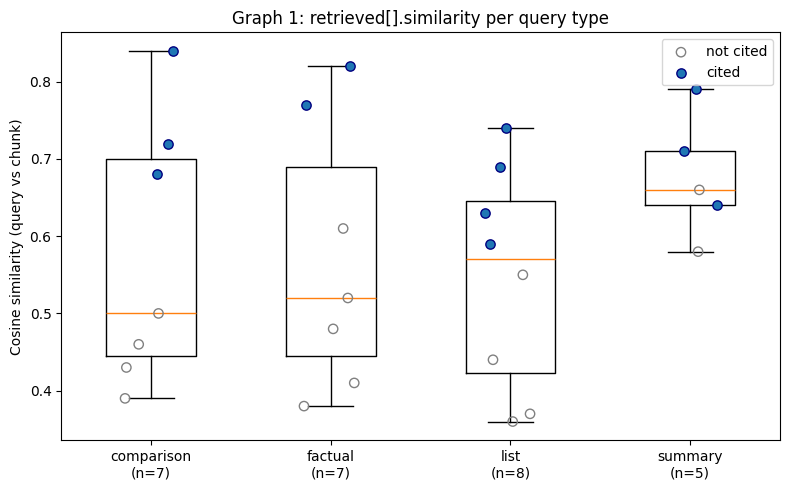

In [5]:
def plot_similarity_by_type(df):
    """Box + strip plot of query-vs-chunk similarity per query type.

    Only 'primary' hits are plotted (other relations have no real score).
    Cited chunks are filled blue dots; non-cited are hollow grey.
    """
    df = df[df["relation"] == "primary"]
    types = sorted(df["query_type"].unique())
    rng = np.random.default_rng(0)
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.boxplot([df.loc[df.query_type == t, "similarity"] for t in types],
               positions=range(len(types)), widths=0.5, showfliers=False)
    for i, t in enumerate(types):
        for is_cited, style in ((False, dict(facecolors="none", edgecolors="grey")),
                                (True, dict(facecolors="tab:blue", edgecolors="navy"))):
            sub = df[(df.query_type == t) & (df.cited == is_cited)]
            ax.scatter(i + rng.uniform(-0.15, 0.15, len(sub)), sub["similarity"], s=45, zorder=3,
                       label=("cited" if is_cited else "not cited") if i == 0 else None, **style)
    ax.set_xticks(range(len(types)))
    ax.set_xticklabels([f"{t}\n(n={(df.query_type == t).sum()})" for t in types])
    ax.set_ylabel("Cosine similarity (query vs chunk)")
    ax.set_title("Graph 1: retrieved[].similarity per query type")
    ax.legend()
    plt.tight_layout()
    plt.show()


plot_similarity_by_type(df_chunks)


## 5. Graph 2: answer vs cited chunks

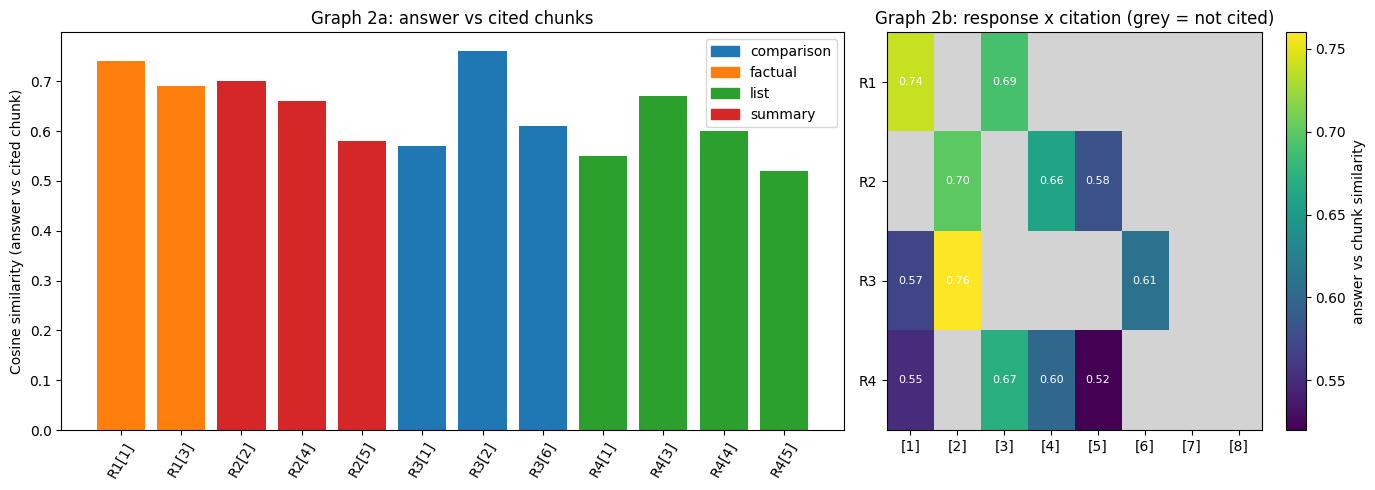

In [6]:
def plot_answer_vs_citations(df, resp_df):
    """Left: answer-vs-cited-chunk similarity bars. Right: response x marker heatmap."""
    cited = df[df["cited"]].copy()
    cited["tag"] = cited["resp"] + "[" + cited["marker"].astype(str) + "]"
    types = sorted(resp_df["query_type"].unique())
    colors = {t: plt.cm.tab10(i) for i, t in enumerate(types)}
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [2, 1.2]})
    ax1.bar(cited["tag"], cited["answer_similarity"].fillna(0),
            color=[colors[t] for t in cited["query_type"]])
    ax1.set_ylabel("Cosine similarity (answer vs cited chunk)")
    ax1.set_title("Graph 2a: answer vs cited chunks")
    ax1.tick_params(axis="x", rotation=60)
    ax1.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=colors[t]) for t in types], labels=types)

    resps = list(resp_df["resp"])
    markers = list(range(1, int(df["marker"].max()) + 1))
    grid = np.full((len(resps), len(markers)), np.nan)
    for _, r in cited.iterrows():
        grid[resps.index(r["resp"]), int(r["marker"]) - 1] = r["answer_similarity"]
    cmap = plt.cm.viridis.copy()
    cmap.set_bad("lightgrey")
    im = ax2.imshow(np.ma.masked_invalid(grid), cmap=cmap, aspect="auto")
    ax2.set_xticks(range(len(markers)))
    ax2.set_xticklabels([f"[{m}]" for m in markers])
    ax2.set_yticks(range(len(resps)))
    ax2.set_yticklabels(resps)
    for (i, j), v in np.ndenumerate(grid):
        if not np.isnan(v):
            ax2.text(j, i, f"{v:.2f}", ha="center", va="center", color="white", fontsize=8)
    ax2.set_title("Graph 2b: response x citation (grey = not cited)")
    fig.colorbar(im, ax=ax2, label="answer vs chunk similarity")
    plt.tight_layout()
    plt.show()


plot_answer_vs_citations(df_chunks, df_resp)
